# Final Investigation Summary and Data Handling Decisions

## Key Findings

1. **Customer metrics:** 753 of 800 customers had stored order metrics matching calculations based on delivered orders. Another 43 matched non-cancelled order metrics but not delivered-order metrics. Four customers matched none of the tested definitions. The source system's exact metric definitions remain unconfirmed.

2. **Product prices:** The global IQR method flagged 163 products as potential outliers. However, category-specific IQR analysis identified no outliers, suggesting that differences in category price distributions influenced the global results.

3. **Order values:** High-value orders appeared across multiple statuses, including shipped, delivered, and cancelled. High monetary values alone were not sufficient evidence of incorrect data.

## Data Handling Decisions

- Preserve all original records.
- Do not replace or remove customer metrics whose definitions remain uncertain.
- Do not remove products or orders solely because their values are statistical outliers.
- Retain order status for subsequent analyses.
- Distinguish delivered, cancelled, and refunded orders when defining business metrics.
- Keep unresolved data quality questions documented rather than assuming a particular business rule.

## Conclusion

The investigations identified a small number of unresolved customer-metric discrepancies and demonstrated that global outlier thresholds can be misleading when product categories have different price distributions. No records were removed or modified during these investigations.

The datasets will proceed to exploratory data analysis, with the documented limitations considered when interpreting results.

In [1]:

# 1. IMPORTS AND DATA LOADING

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = Path("../data/raw")

datasets = {
    "products": pd.read_csv(RAW_DIR / "products.csv"),
    "customers": pd.read_csv(RAW_DIR / "customers.csv"),
    "orders": pd.read_csv(RAW_DIR / "orders.csv"),
    "order_items": pd.read_csv(RAW_DIR / "order_items.csv"),
    "reviews": pd.read_csv(RAW_DIR / "reviews.csv"),
}

products = datasets["products"]
customers = datasets["customers"]
orders = datasets["orders"]
order_items = datasets["order_items"]
reviews = datasets["reviews"]

print("Datasets loaded successfully!\n")

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


Datasets loaded successfully!

products: 2,000 rows × 19 columns
customers: 800 rows × 13 columns
orders: 3,000 rows × 21 columns
order_items: 6,219 rows × 10 columns
reviews: 2,500 rows × 10 columns


In [2]:

# 2. DESCRIPTIVE STATISTICS

numeric_columns = {
    "products": products.select_dtypes(include="number"),
    "customers": customers.select_dtypes(include="number"),
    "orders": orders.select_dtypes(include="number"),
    "order_items": order_items.select_dtypes(include="number"),
    "reviews": reviews.select_dtypes(include="number"),
}

for name, numeric_df in numeric_columns.items():
    print(f"\n{'=' * 70}")
    print(f"{name.upper()} — DESCRIPTIVE STATISTICS")
    print("=" * 70)

    display(numeric_df.describe().round(2))



PRODUCTS — DESCRIPTIVE STATISTICS


,id,category_id,price,compare_at_price,weight_g,rating,review_count
count,2000.00,2000.00,2000.00,355.00,2000.00,1441.00,2000.00
mean,1000.50,4.47,468.16,636.43,5979.05,3.92,1.25
std,577.49,2.28,636.59,927.54,3400.46,1.00,1.10
min,1.00,1.00,5.14,8.65,87.00,1.00,0.00
25%,500.75,2.00,86.64,108.60,3012.50,3.30,0.00
50%,1000.50,4.00,240.72,286.98,5906.50,4.00,1.00
75%,1500.25,6.00,559.28,722.44,8836.25,5.00,2.00
max,2000.00,8.00,3492.50,5049.64,11993.00,5.00,6.00



CUSTOMERS — DESCRIPTIVE STATISTICS


,id,orders_count,total_spent
count,800.00,800.00,800.00
mean,400.50,3.40,4855.65
std,231.08,1.95,4275.98
min,1.00,0.00,0.00
25%,200.75,2.00,1513.62
50%,400.50,3.00,3877.88
75%,600.25,5.00,6892.04
max,800.00,12.00,30063.98



ORDERS — DESCRIPTIVE STATISTICS


,id,customer_id,subtotal,shipping,tax,discount,total
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,1500.50,399.69,1346.47,9.71,92.70,22.12,1426.76
std,866.17,229.82,1750.11,7.42,120.91,100.55,1848.10
min,1.00,1.00,5.14,0.00,0.36,0.00,8.87
25%,750.75,200.00,268.98,5.99,18.07,0.00,287.22
50%,1500.50,396.00,744.48,5.99,51.05,0.00,792.37
75%,2250.25,600.00,1696.45,14.99,116.60,0.00,1787.86
max,3000.00,800.00,16027.02,29.99,1121.89,2421.08,17154.90



ORDER_ITEMS — DESCRIPTIVE STATISTICS


,id,order_id,product_id,quantity,unit_price,line_total
count,6219.00,6219.00,6219.00,6219.00,6219.00,6219.00
mean,3110.00,1504.46,1000.19,1.43,451.94,649.53
std,1795.41,864.69,576.94,0.75,623.05,1084.54
min,1.00,1.00,1.00,1.00,5.14,5.14
25%,1555.50,758.50,492.00,1.00,82.64,108.55
50%,3110.00,1505.00,1003.00,1.00,220.56,280.76
75%,4664.50,2253.00,1506.50,2.00,536.27,705.10
max,6219.00,3000.00,2000.00,4.00,3492.50,13970.00



REVIEWS — DESCRIPTIVE STATISTICS


,id,product_id,customer_id,rating,helpful_votes
count,2500.00,2500.00,2500.00,2500.00,2500.00
mean,1250.50,992.71,397.30,3.91,4.57
std,721.83,580.91,224.84,1.20,8.91
min,1.00,1.00,1.00,1.00,0.00
25%,625.75,479.00,206.00,3.00,0.00
50%,1250.50,979.00,398.00,4.00,1.00
75%,1875.25,1497.00,584.00,5.00,4.00
max,2500.00,2000.00,800.00,5.00,40.00


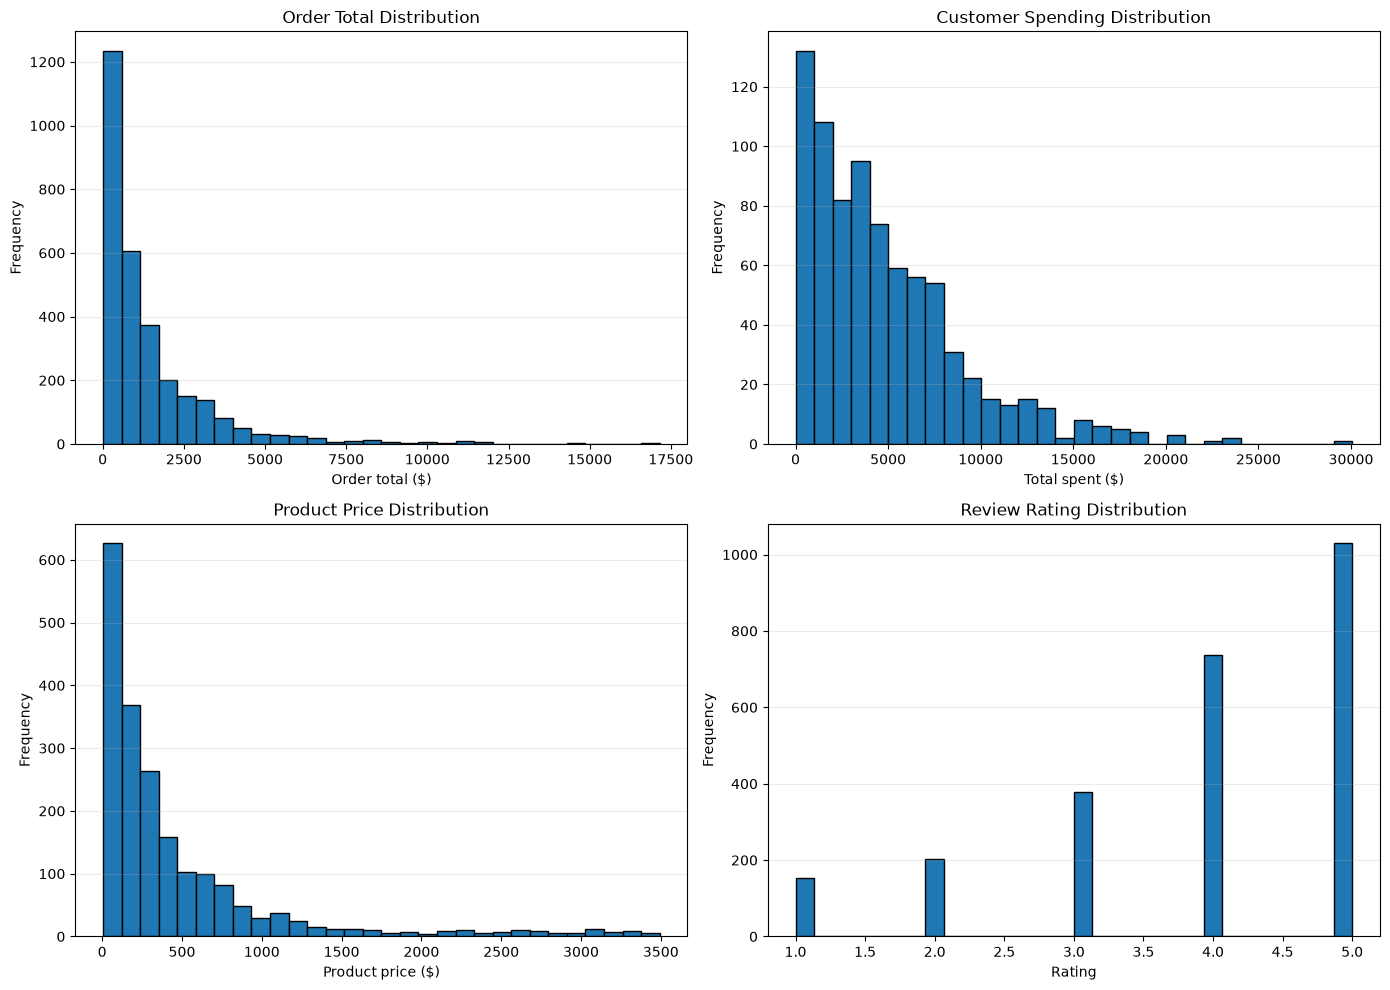

In [3]:

# STEP 3 — DISTRIBUTION HISTOGRAMS

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plot_configs = [
    (orders["total"], "Order Total Distribution", "Order total ($)"),
    (customers["total_spent"], "Customer Spending Distribution", "Total spent ($)"),
    (products["price"], "Product Price Distribution", "Product price ($)"),
    (reviews["rating"], "Review Rating Distribution", "Rating"),
]

for ax, (series, title, xlabel) in zip(axes.flat, plot_configs):
    ax.hist(series.dropna(), bins=30, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


In [4]:

# STEP 4 — CATEGORICAL DISTRIBUTIONS

categorical_columns = {
    "products": ["category_id", "brand", "color", "status", "in_stock"],
    "customers": ["tier", "marketing_opt_in"],
    "orders": ["status", "payment_method", "shipping_method"],
    "reviews": ["rating"],
}

for dataset_name, columns in categorical_columns.items():
    df = datasets[dataset_name]

    for column in columns:
        print(f"\n{dataset_name.upper()} — {column}")

        counts = df[column].value_counts(dropna=False)
        percentages = (
            df[column].value_counts(normalize=True, dropna=False) * 100
        )

        summary = pd.DataFrame({
            "count": counts,
            "percentage": percentages.round(2)
        })

        display(summary)



PRODUCTS — category_id


,count,percentage
category_id,,
5,261,13.05
2,260,13.00
3,260,13.00
8,253,12.65
6,251,12.55
4,246,12.30
1,244,12.20
7,225,11.25



PRODUCTS — brand


,count,percentage
brand,,
Pulse,88,4.40
Quill,78,3.90
Meridian House,77,3.85
Linden,75,3.75
Kettleworth,72,3.60
Pebble,72,3.60
Kestrel,71,3.55
Marrow,70,3.50
Granite,69,3.45



PRODUCTS — color


...

,count,percentage
payment_method,,
card,2080,69.33
paypal,550,18.33
bank_transfer,207,6.90
cash_on_delivery,163,5.43



ORDERS — shipping_method


,count,percentage
shipping_method,,
standard,1817,60.57
express,732,24.40
overnight,243,8.10
pickup,208,6.93



REVIEWS — rating


,count,percentage
rating,,
5,1029,41.16
4,737,29.48
3,379,15.16
2,202,8.08
1,153,6.12


### Categorical Distribution — Key Findings

- **Product categories:** The eight categories are relatively evenly represented, each accounting for 11.25%–13.05% of products.
- **Stock availability:** 84.9% of products are marked as in stock.
- **Customer tiers:** Standard customers represent 59% of the customer base, while platinum customers represent 6%.
- **Marketing consent:** 55.88% of customers have opted in to marketing, compared with 44.12% who have not.
- **Order status:** Delivered orders account for 89.17% of all records. Cancelled and refunded orders represent 5.77% and 3.47%, respectively.
- **Payment methods:** Card payments are the most frequent (69.33%), followed by PayPal (18.33%).
- **Shipping methods:** Standard shipping is the most common option (60.57%).
- **Customer reviews:** 70.64% of reviews have ratings of 4 or 5.

These distributions describe the dataset and help identify variables worth investigating further. They do not, on their own, establish causal relationships or explain customer preferences.

,orders_count,total_spent
orders_count,1.000,0.616
total_spent,0.616,1.000


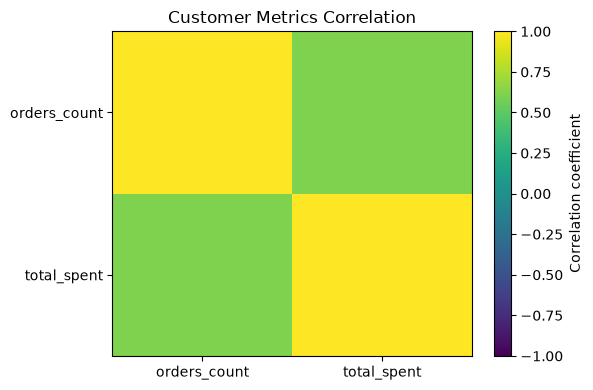

In [5]:

# STEP 5 — CUSTOMER CORRELATION ANALYSIS

customer_numeric = customers[
    ["orders_count", "total_spent"]
].corr()

display(customer_numeric.round(3))

plt.figure(figsize=(6, 4))
plt.imshow(customer_numeric, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation coefficient")
plt.xticks(range(len(customer_numeric.columns)), customer_numeric.columns)
plt.yticks(range(len(customer_numeric.index)), customer_numeric.index)
plt.title("Customer Metrics Correlation")
plt.tight_layout()
plt.show()


,order_count,median_order_total,mean_order_total,total_order_value
payment_method,,,,
bank_transfer,207,844.02,1380.38,285739.60
card,2080,798.04,1437.25,2989489.52
paypal,550,744.04,1393.11,766209.61
cash_on_delivery,163,684.39,1465.29,238841.88


<Figure size 900x500 with 0 Axes>

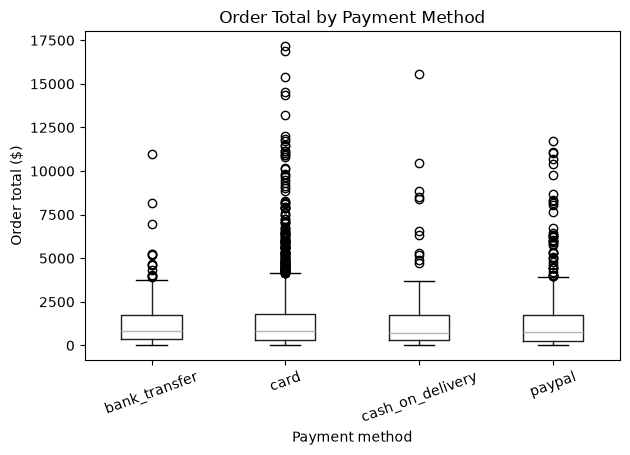

In [6]:

# STEP 6 — ORDER VALUE BY PAYMENT METHOD

payment_summary = (
    orders.groupby("payment_method")
    .agg(
        order_count=("id", "count"),
        median_order_total=("total", "median"),
        mean_order_total=("total", "mean"),
        total_order_value=("total", "sum")
    )
    .sort_values("median_order_total", ascending=False)
    .round(2)
)

display(payment_summary)

plt.figure(figsize=(9, 5))

orders.boxplot(
    column="total",
    by="payment_method",
    grid=False
)

plt.title("Order Total by Payment Method")
plt.suptitle("")
plt.xlabel("Payment method")
plt.ylabel("Order total ($)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Order Value by Payment Method

Order values were compared across payment methods using order count, median, mean, and total recorded order value.

- Bank transfer had the highest median order total ($844.02).
- Cash on delivery had the highest mean order total ($1,465.29), despite having the lowest median ($684.39). This pattern is consistent with a right-skewed distribution influenced by high-value orders.
- Card payments accounted for the largest number of orders (2,080) and the highest total recorded order value ($2,989,489.52).
- The mean exceeded the median for every payment method, suggesting that high-value orders influenced average order values.

These are descriptive associations, not evidence that payment method causes differences in spending. Total recorded order value may also include cancelled or refunded orders, so it should not automatically be interpreted as realized revenue.

,order_count,median_order_total,mean_order_total,total_order_value
shipping_method,,,,
pickup,208,827.84,1573.74,327338.60
express,732,809.32,1518.96,1111881.60
standard,1817,787.22,1400.56,2544817.08
overnight,243,648.14,1219.11,296243.33


<Figure size 900x500 with 0 Axes>

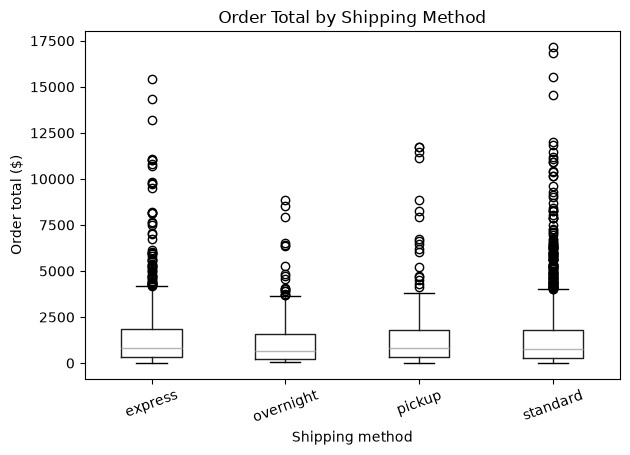

In [7]:

# STEP 7 — ORDER VALUE BY SHIPPING METHOD

shipping_summary = (
    orders.groupby("shipping_method")
    .agg(
        order_count=("id", "count"),
        median_order_total=("total", "median"),
        mean_order_total=("total", "mean"),
        total_order_value=("total", "sum")
    )
    .sort_values("median_order_total", ascending=False)
    .round(2)
)

display(shipping_summary)

plt.figure(figsize=(9, 5))

orders.boxplot(
    column="total",
    by="shipping_method",
    grid=False
)

plt.title("Order Total by Shipping Method")
plt.suptitle("")
plt.xlabel("Shipping method")
plt.ylabel("Order total ($)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Order Value by Shipping Method

Order values were compared across shipping methods.

- Pickup had the highest median order total ($827.84) and mean order total ($1,573.74).
- Standard shipping was the most common method, accounting for 1,817 orders (approximately 60.6%).
- Overnight shipping had the lowest median ($648.14) and mean ($1,219.11).
- Mean order values exceeded medians across all four methods, suggesting that higher-value orders influenced the averages.

These findings describe associations within the dataset. They do not establish that shipping method causes differences in order value. Order status and other customer or product characteristics may also influence the results.

,customer_count,median_spending,mean_spending,median_orders,mean_orders
tier,,,,,
silver,166,4530.96,5640.75,4.0,3.69
gold,114,4399.81,5164.81,4.0,3.73
platinum,48,3828.46,4648.68,4.0,3.52
standard,472,3388.15,4525.92,3.0,3.21


<Figure size 900x500 with 0 Axes>

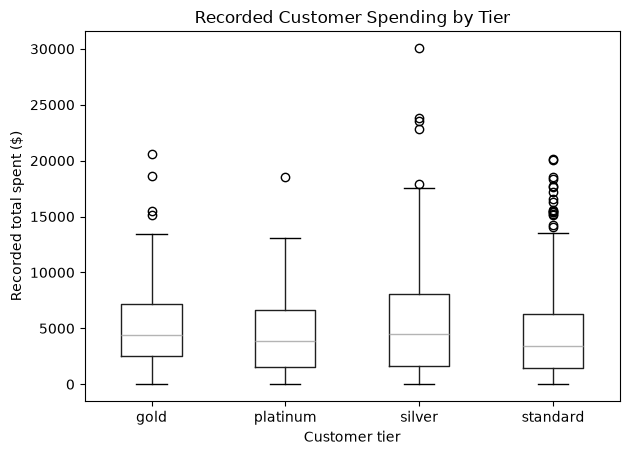

In [8]:

# STEP 8 — CUSTOMER SPENDING BY TIER

tier_summary = (
    customers.groupby("tier")
    .agg(
        customer_count=("id", "count"),
        median_spending=("total_spent", "median"),
        mean_spending=("total_spent", "mean"),
        median_orders=("orders_count", "median"),
        mean_orders=("orders_count", "mean")
    )
    .sort_values("median_spending", ascending=False)
    .round(2)
)

display(tier_summary)

plt.figure(figsize=(9, 5))

customers.boxplot(
    column="total_spent",
    by="tier",
    grid=False
)

plt.title("Recorded Customer Spending by Tier")
plt.suptitle("")
plt.xlabel("Customer tier")
plt.ylabel("Recorded total spent ($)")
plt.tight_layout()
plt.show()


### Customer Spending by Tier

Recorded customer spending and order counts were compared across customer tiers.

- Silver customers had the highest median spending ($4,530.96) and mean spending ($5,640.75).
- Standard customers represented the largest group, with 472 customers (59% of the dataset).
- Platinum customers did not have the highest recorded spending; their median spending was $3,828.46.
- The median order count was four for Silver, Gold, and Platinum customers, compared with three for Standard customers.

The results do not show a simple increasing relationship between tier level and recorded spending. The tier assignment rules are unknown, and previously identified inconsistencies in customer-level metrics should be considered when interpreting these findings.

,customer_count,median_spending,mean_spending,median_orders,mean_orders
marketing_opt_in,,,,,
False,353,3869.32,4873.54,3.0,3.49
True,447,3880.06,4841.53,3.0,3.34


<Figure size 700x500 with 0 Axes>

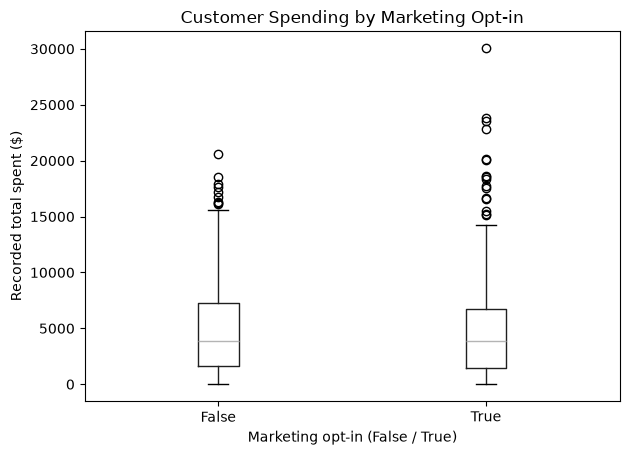

In [9]:

# STEP 9 — MARKETING OPT-IN AND CUSTOMER SPENDING

marketing_summary = (
    customers.groupby("marketing_opt_in")
    .agg(
        customer_count=("id", "count"),
        median_spending=("total_spent", "median"),
        mean_spending=("total_spent", "mean"),
        median_orders=("orders_count", "median"),
        mean_orders=("orders_count", "mean")
    )
    .round(2)
)

display(marketing_summary)

plt.figure(figsize=(7, 5))

customers.boxplot(
    column="total_spent",
    by="marketing_opt_in",
    grid=False
)

plt.title("Customer Spending by Marketing Opt-in")
plt.suptitle("")
plt.xlabel("Marketing opt-in (False / True)")
plt.ylabel("Recorded total spent ($)")
plt.tight_layout()
plt.show()


### Customer Spending by Marketing Opt-in

Customer spending and order counts were compared between customers who opted in to marketing and those who did not.

- Customers who opted in had a median recorded spending of $3,880.06, compared with $3,869.32 for those who did not.
- Customers who did not opt in had a slightly higher mean spending ($4,873.54 versus $4,841.53).
- Both groups had a median of three orders.

The descriptive differences were small. These results do not establish a meaningful relationship between marketing consent and spending, nor do they show that marketing consent causes changes in customer behaviour. Statistical testing may be used later to assess whether observed group differences are distinguishable from random variation.

,rating,review_count,percentage
0,1,153,6.12
1,2,202,8.08
2,3,379,15.16
3,4,737,29.48
4,5,1029,41.16


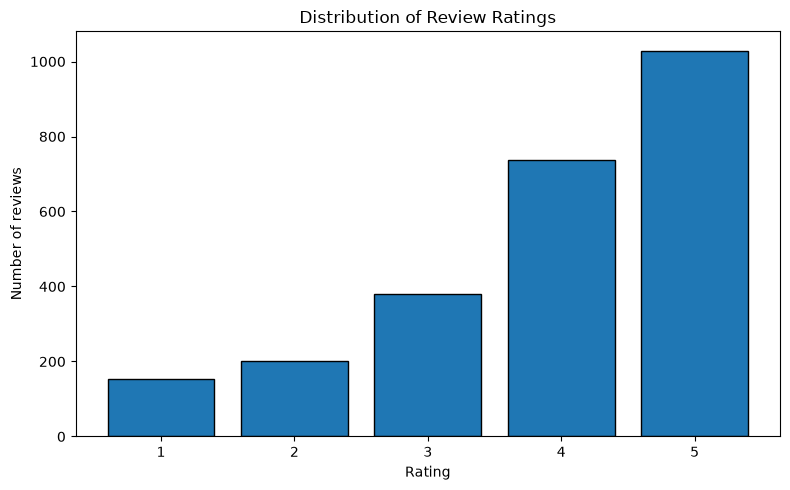

4–5 star reviews: 70.64%
1–2 star reviews: 14.20%


In [10]:

# STEP 10 — REVIEW RATING SUMMARY

rating_summary = (
    reviews["rating"]
    .value_counts()
    .sort_index()
    .rename_axis("rating")
    .reset_index(name="review_count")
)

rating_summary["percentage"] = (
    rating_summary["review_count"] / len(reviews) * 100
).round(2)

display(rating_summary)

plt.figure(figsize=(8, 5))
plt.bar(
    rating_summary["rating"],
    rating_summary["review_count"],
    edgecolor="black"
)

plt.title("Distribution of Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of reviews")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

positive_reviews = reviews["rating"].isin([4, 5]).mean() * 100
negative_reviews = reviews["rating"].isin([1, 2]).mean() * 100

print(f"4–5 star reviews: {positive_reviews:.2f}%")
print(f"1–2 star reviews: {negative_reviews:.2f}%")


### Review Rating Distribution

The dataset contains 2,500 product reviews, with ratings ranging from one to five stars.

- Five-star reviews were the most frequent, accounting for 41.16% of all reviews.
- Four-star reviews represented 29.48%.
- Combined, four- and five-star reviews accounted for 70.64% of reviews.
- One- and two-star reviews represented 14.20%, while three-star reviews accounted for 15.16%.

Overall, high ratings were more common than low ratings in this dataset. However, the distribution alone cannot establish overall customer satisfaction or rule out selection bias in the reviews.

,review_count,mean_rating,median_rating,five_star_percentage
category_id,,,,
2,321,3.98,4.0,43.61
3,357,3.97,4.0,43.14
7,291,3.93,4.0,38.49
1,310,3.90,4.0,41.61
4,309,3.90,4.0,40.13
5,322,3.89,4.0,42.55
8,294,3.87,4.0,39.12
6,296,3.86,4.0,39.86


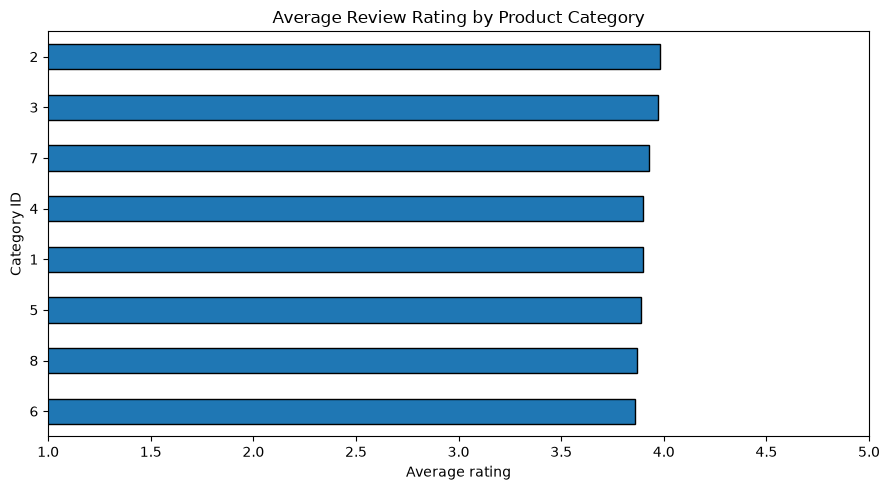

In [11]:

# STEP 11 — REVIEW RATINGS BY PRODUCT CATEGORY

reviews_with_category = reviews.merge(
    products[["id", "category_id"]],
    left_on="product_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

category_rating_summary = (
    reviews_with_category
    .groupby("category_id")
    .agg(
        review_count=("rating", "count"),
        mean_rating=("rating", "mean"),
        median_rating=("rating", "median"),
        five_star_percentage=(
            "rating",
            lambda x: x.eq(5).mean() * 100
        )
    )
    .sort_values("mean_rating", ascending=False)
    .round(2)
)

display(category_rating_summary)

plt.figure(figsize=(9, 5))
category_rating_summary["mean_rating"].sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Average Review Rating by Product Category")
plt.xlabel("Average rating")
plt.ylabel("Category ID")
plt.xlim(1, 5)
plt.tight_layout()
plt.show()


### Review Ratings by Product Category

Average review ratings were compared across the eight product categories.

- Category 2 had the highest mean rating (3.98) and the highest proportion of five-star reviews (43.61%).
- Category 3 had the second-highest mean rating (3.97).
- Category 6 had the lowest mean rating (3.86).
- The median rating was four in every category.
- Mean ratings ranged from 3.86 to 3.98, indicating relatively small descriptive differences across categories.

These results suggest that review ratings were broadly similar across product categories. Further statistical testing would be required to determine whether the observed differences are statistically meaningful. Category names were unavailable, so results are reported using category IDs.

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_33444\1526525163.py:13: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period("M")


,order_month,order_count,median_order_total,mean_order_total
0,2025-09,240,891.52,1443.09
1,2025-10,242,781.72,1353.43
2,2025-11,202,726.82,1340.03
3,2025-12,261,721.39,1399.82
4,2026-01,290,860.24,1379.63
5,2026-02,246,722.96,1413.09
6,2026-03,278,799.20,1362.55
7,2026-04,257,748.52,1355.05
8,2026-05,200,674.05,1631.33
9,2026-06,217,775.08,1417.93


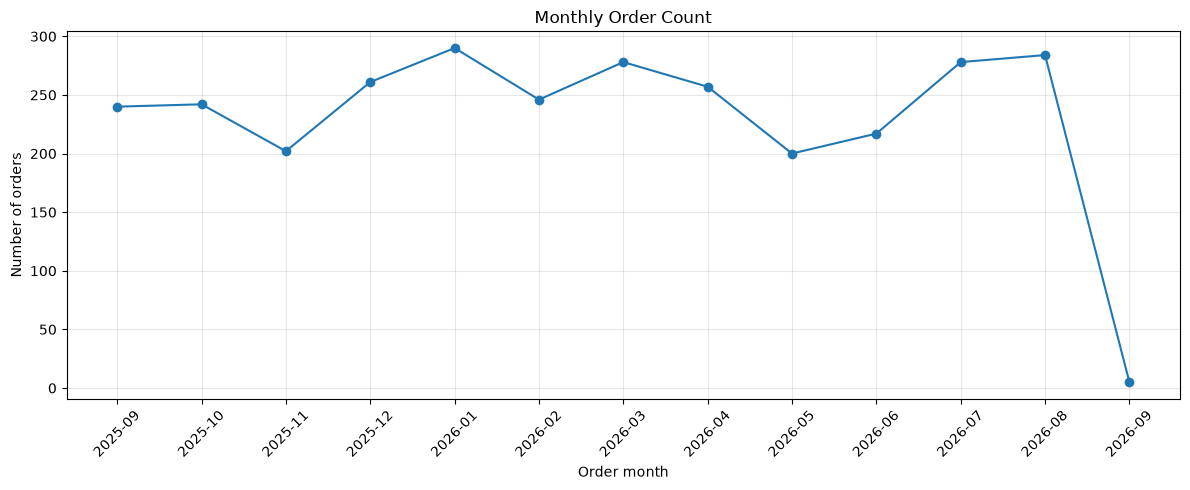

In [12]:

# STEP 12 — MONTHLY ORDER DISTRIBUTION

orders_time = orders.copy()

orders_time["placed_at"] = pd.to_datetime(
    orders_time["placed_at"],
    errors="coerce",
    utc=True
)

orders_time["order_month"] = (
    orders_time["placed_at"]
    .dt.to_period("M")
    .astype("string")
)

monthly_orders = (
    orders_time
    .groupby("order_month")
    .agg(
        order_count=("id", "count"),
        median_order_total=("total", "median"),
        mean_order_total=("total", "mean")
    )
    .reset_index()
    .sort_values("order_month")
)

display(monthly_orders.round(2))

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_orders["order_month"],
    monthly_orders["order_count"],
    marker="o"
)

plt.title("Monthly Order Count")
plt.xlabel("Order month")
plt.ylabel("Number of orders")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

# STEP 13 — FINAL UNIVARIATE EDA SUMMARY

print("DATASET OVERVIEW")
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

print("\nORDER DATE RANGE")
print(f"First order: {orders_time['placed_at'].min()}")
print(f"Last order:  {orders_time['placed_at'].max()}")

print("\nORDER VALUE")
print(f"Median order total: ${orders['total'].median():,.2f}")
print(f"Mean order total:   ${orders['total'].mean():,.2f}")

print("\nPRODUCTS")
print(f"Median product price: ${products['price'].median():,.2f}")
print(f"Products in stock: {products['in_stock'].mean() * 100:.2f}%")

print("\nCUSTOMERS")
print(f"Most common tier: {customers['tier'].mode().iloc[0]}")
print(f"Marketing opt-in: {customers['marketing_opt_in'].mean() * 100:.2f}%")

print("\nORDERS")
print(f"Most common payment method: {orders['payment_method'].mode().iloc[0]}")
print(f"Most common shipping method: {orders['shipping_method'].mode().iloc[0]}")

print("\nREVIEWS")
print(f"Mean rating: {reviews['rating'].mean():.2f}/5")
print(f"4–5 star reviews: {reviews['rating'].isin([4, 5]).mean() * 100:.2f}%")


DATASET OVERVIEW
products: 2,000 rows × 19 columns
customers: 800 rows × 13 columns
orders: 3,000 rows × 21 columns
order_items: 6,219 rows × 10 columns
reviews: 2,500 rows × 10 columns

ORDER DATE RANGE
First order: 2025-09-01 12:24:43+00:00
Last order:  2026-09-01 11:06:02+00:00

ORDER VALUE
Median order total: $792.37
Mean order total:   $1,426.76

PRODUCTS
Median product price: $240.72
Products in stock: 84.90%

CUSTOMERS
Most common tier: standard
Marketing opt-in: 55.88%

ORDERS
Most common payment method: card
Most common shipping method: standard

REVIEWS
Mean rating: 3.91/5
4–5 star reviews: 70.64%


## Key Findings — Univariate and Exploratory Analysis

- Product categories and brands were relatively evenly represented in the dataset.
- Most products were marked as in stock.
- Order totals and customer spending showed differences between their means and medians, suggesting that high-value observations may influence averages.
- Card payments and standard shipping were the most common recorded options.
- Customer spending differed across tiers, although the tier pattern was not consistently increasing.
- Customers who opted into marketing had similar median spending to those who did not.
- Review ratings were generally positive, with most reviews receiving four or five stars.
- Average review ratings were similar across product categories.
- Monthly order counts varied. September 2026 had very few recorded orders and may represent an incomplete month.

### Limitations

This notebook focuses on descriptive analysis. Observed differences do not establish causation or statistical significance. Customer-level spending metrics have unresolved inconsistencies identified during data quality investigation. Order totals also include multiple order statuses, so they should not automatically be interpreted as realized revenue.